# Portfolio sintetico multi-round: local greedy + SCIP

Analisi degli artifact persistiti, senza eseguire la pipeline nel notebook. L'istanza predefinita contiene 30 asset, contro i 5 degli esempi single-pass.

```bash
poetry install --with notebooks,experiments
poetry run python -m qreduce.experiments.portfolio_multi_round --run-id multi-round-001
```

Usare `--asset-count 60` per aumentare ulteriormente la dimensione e un nuovo `--run-id` per ogni pubblicazione. SCIP richiede PySCIPOpt. Il run può terminare con una failure normalizzata se il backend non è disponibile.

**Attenzione:** tre è il numero massimo di round, non quello garantito. La pipeline si arresta già al primo successo o successo parziale; anche un problema grande può quindi produrre un solo round.

In [ ]:
from pathlib import Path

from qreduce.experiments import load_experiment_run
from qreduce.experiments.portfolio_multi_round import load_multi_round_correlation_data
from qreduce.notebooks.plots import plot_correlation_matrix
from qreduce.notebooks.presentation import display_records, display_vertical

repository_root = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / "pyproject.toml").is_file()),
    None,
)
if repository_root is None:
    raise RuntimeError("Run this notebook from inside the QReduce repository.")

run_directory = repository_root / "outputs/synthetic-portfolio-multi-round/multi-round-001"
artifacts = load_experiment_run(run_directory)
if not artifacts.has_reduction:
    raise ValueError("The selected artifact has no reduction rounds.")
result = artifacts.result

ValueError: The selected artifact is not a multi-round run.

## 1. Configurazione, provenance e stato

In [ ]:
display_vertical(dict(artifacts.manifest), title="Manifest")
display_vertical(dict(artifacts.config["reduction"]), title="Policy di riduzione")
display_vertical(dict(result["run_result"]), title="Risultato normalizzato")
display_vertical(dict(result["metrics"]), title="Metriche complessive")

Manifest


,campo,valore
0,artifact_schema_version,1.0
1,config_hash,a40f5b44416e3b336990cd4413f82b354478c56988a08b...
2,created_at,2026-11-13T10:39:51.389504Z
3,experiment_id,synthetic-portfolio-multi-round
4,files,"{\n ""config_used.json"": ""a40f5b44416e3b336990..."
5,model_export,None
6,policy_provenance,"{\n ""declared_instance_class"": null,\n ""decl..."
7,producer_version,0.1.0
8,recovery_attempt_count,0
9,round_count,1


Policy di riduzione


,campo,valore
0,candidate_domain_max_items,30
1,candidate_domain_min_items,1
2,max_end_to_end_runtime_seconds,60.0
3,max_recovery_attempts,0
4,max_reduction_rounds,3
5,min_reduction_ratio,0.1
6,num_source_mis_candidates,1
7,recovery_policy_on_domain_too_small,fail
8,recovery_policy_on_infeasible,fail
9,target_binary_variables,0


Risultato normalizzato


,campo,valore
0,adoption_status,adopted
1,classical_solver_status,optimal
2,config_hash,a40f5b44416e3b336990cd4413f82b354478c56988a08b...
3,diagnostic_message,NaN
4,input_hash,3a69bd03fbd6eeb9a09ede10320e3ac01fb3096a847602...
5,policy_hash,NaN
6,postcheck_status,passed
7,round_results,"[\n {\n ""metadata"": {\n ""excluded_cou..."
8,run_id,multi-round-001
9,run_status,success


Metriche complessive


,campo,valore
0,cumulative_reduction_ratio,0.666667
1,end_to_end_runtime_seconds,0.082049
2,recovery_attempt_count,0.000000
3,round_count,1.000000


## 2. Problema e dimensioni

Le correlazioni e gli archi rappresentano una euristica di riduzione, non vincoli hard del portfolio.

In [ ]:
display_vertical({
    "asset_count": len(artifacts.problem["asset_ids"]),
    "original_variable_counts": result["original_variable_counts"],
    "residual_variable_counts": result["residual_variable_counts"],
    "round_count": len(artifacts.round_results),
    "recovery_attempt_count": len(artifacts.recovery_attempts),
}, title="Dimensioni")

Dimensioni


,campo,valore
0,asset_count,30
1,original_variable_counts,"{\n ""binary_free"": 30,\n ""continuous_free"": ..."
2,residual_variable_counts,"{\n ""binary_free"": 10,\n ""continuous_free"": ..."
3,round_count,1
4,recovery_attempt_count,0


## Matrice delle correlazioni degli asset

I contorni rossi indicano gli archi effettivamente persistiti per il primo round. Se la compilazione non ha prodotto un grafo, la matrice resta visibile senza contorni. Per istanze grandi i valori numerici nelle celle sono omessi per leggibilità.

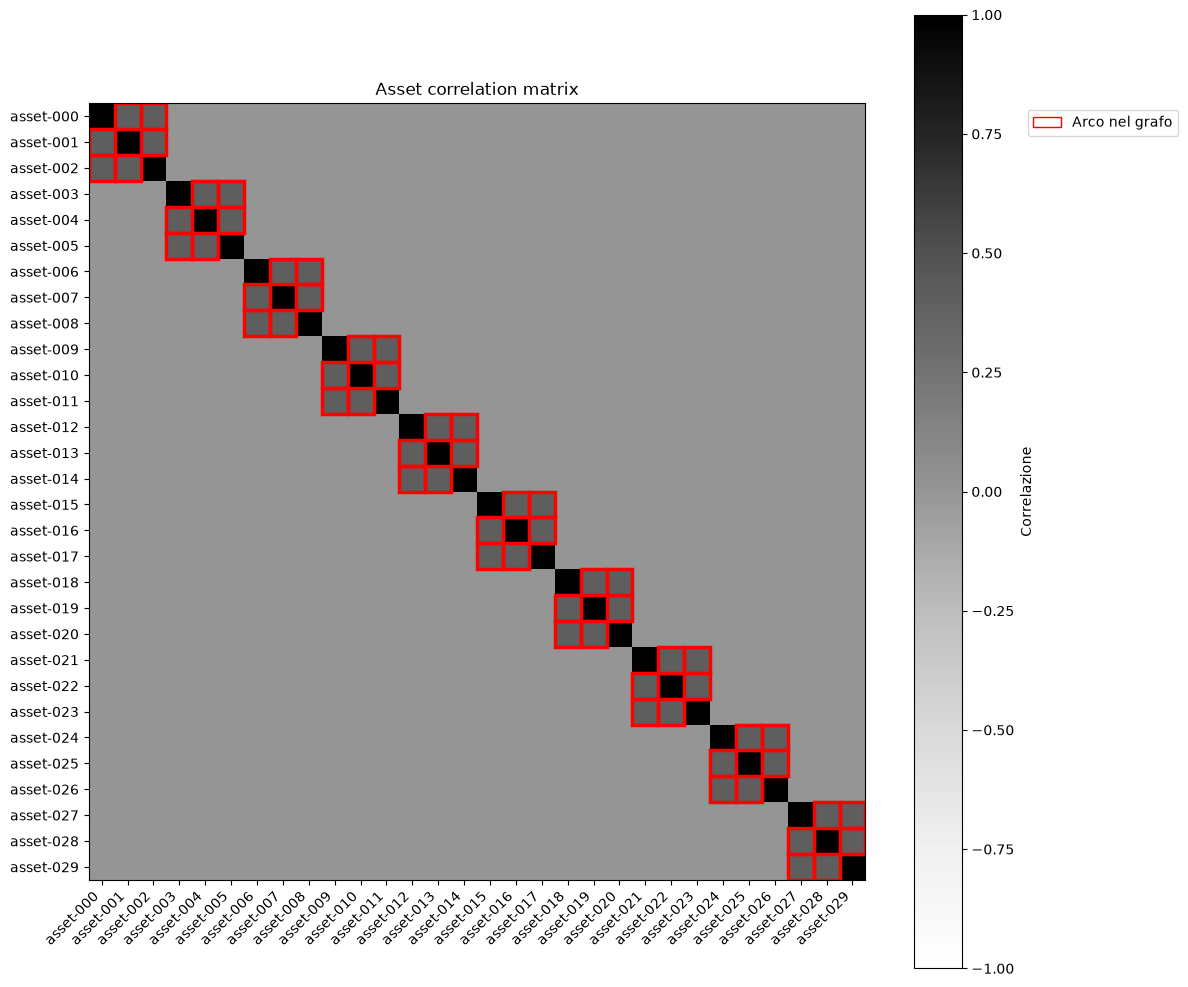

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

asset_ids, correlation, graph = load_multi_round_correlation_data(run_directory)
fig, ax = plot_correlation_matrix(asset_ids, correlation, graph, threshold=None)
plt.show()

## 3. Risultati per round

Ogni round presenta il proprio stato, le metriche, il dominio candidato e gli esiti MIS, solve e post-check. I campi possono essere assenti in caso di failure.

In [ ]:
for index, round_result in enumerate(artifacts.round_results):
    print(f"Round {index}")
    display_vertical(round_result["run_result"], title="Stato")
    display_vertical(round_result["metrics"], title="Metriche")
    display_vertical({
        "retained_item_ids": round_result["retained_item_ids"],
        "fixing_manifest": round_result["fixing_manifest"],
        "mis_compilation_result": round_result["mis_compilation_result"],
        "mis_execution_result": round_result["mis_execution_result"],
        "classical_result": round_result["classical_result"],
        "postcheck_result": round_result["postcheck_result"],
    }, title="Dettagli del round")

Round 0
Stato


,campo,valore
0,adoption_status,adopted
1,classical_solver_status,optimal
2,config_hash,a40f5b44416e3b336990cd4413f82b354478c56988a08b...
3,diagnostic_message,NaN
4,input_hash,NaN
5,policy_hash,NaN
6,postcheck_status,passed
7,round_results,[]
8,run_id,multi-round-001
9,run_status,success


Metriche


,campo,valore
0,best_bound,-0.068438
1,candidate_domain_size,10
2,classical_runtime_seconds,0.025501
3,classical_solver_claimed_feasible,True
4,end_to_end_runtime_seconds,0.082003
5,mis_backend_family,classical_heuristic
6,mis_backend_id,greedy_mis
7,mis_compilation_runtime_seconds,0.000006
8,mis_device_id,None
9,mis_execution_mode,local


Dettagli del round


,campo,valore
0,retained_item_ids,"[\n ""asset-000"",\n ""asset-003"",\n ""asset-00..."
1,fixing_manifest,"{\n ""entries"": [\n {\n ""fixing_origin..."
2,mis_compilation_result,"{\n ""compiled_job"": {\n ""backend_family"": ..."
3,mis_execution_result,"{\n ""backend_family"": ""classical_heuristic"",\..."
4,classical_result,"{\n ""best_bound"": -0.06843794250488282,\n ""c..."
5,postcheck_result,"{\n ""failure_reasons"": [],\n ""fixed_variable..."


## 4. Fixing cumulativi, recovery e soluzione

Il dominio mantenuto non coincide necessariamente con la selezione finale. La riduzione euristica non certifica l’ottimo del problema originale.

In [ ]:
display_vertical({
    "final_retained_item_ids": result["final_retained_item_ids"],
    "cumulative_fixing_manifest": result["cumulative_fixing_manifest"],
    "classical_result": result["classical_result"],
    "original_problem_optimality_claim": result["original_problem_optimality_claim"],
}, title="Esito finale")
display_records(artifacts.recovery_attempts, record_label="recovery")

Esito finale


,campo,valore
0,final_retained_item_ids,"[\n ""asset-000"",\n ""asset-003"",\n ""asset-00..."
1,cumulative_fixing_manifest,"{\n ""entries"": [\n {\n ""fixing_origin..."
2,classical_result,"{\n ""best_bound"": -0.06843794250488282,\n ""c..."
3,original_problem_optimality_claim,none


,recovery,campo,valore
